# GRANAP, 2: change a parameter

**What you will learn:** list GRANAP's parameters with their units, change one, compare two sections, deal with the
model's random part, and use another preset (a dicotyledon root).

**You need:** tutorial 1. **Run time:** about 40 seconds.

## 1. The parameters

A **parameter** is a number that describes the anatomy: the number of cortex layers, the diameter of the stele...
GRANAP groups them by **section** of the anatomy (`cortex`, `stele`, `xylem`...), each with its **fields**.
`parameters()` lists them all with their value, unit and description; `parameters(main_only=True)` keeps the main
ones, those GRANAP's presets change.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.granap.simulation import parameters, simulate

main = parameters(main_only=True)
main[["section", "field", "value", "unit", "description"]]

,section,field,value,unit,description
0,planttype,value,1,,"1 monocotyledon, 2 dicotyledon, 3 conifer needle"
1,planttype,organ,root,,"The organ: root, stem, leaf or needle"
2,stele,thickness,0.27,mm,Diameter (mm) of the central region: a root's ...
3,stele,cell_diameter,0.01,mm,Cell diameter at the region periphery (lower b...
4,stele,cell_diameter_center,0.02,mm,Cell diameter at the region center (upper boun...
5,xylem,vessel_diameter,0.06,mm,Metaxylem vessel diameter (upper bound of the ...
6,xylem,vessel_diameter_min,0.01,mm,Lower bound / floor of the vessel size gradient.
7,xylem,n_vascular_peak,5,count,"Number of xylem star arms (poles), alternating..."
8,xylem,n_vascular_bundles,5,count,Number of metaxylem vessels. 0 is legal: the a...
9,xylem,n_protoxylem,10,count,"Protoxylem bundle count, set directly. Indepen..."


The main parameters of a root in plain words, with their default values in micrometres:

| section | field | what it controls | default |
|---|---|---|---|
| `stele` | `thickness` | diameter of the stele, the central cylinder | 270 µm |
| `stele` | `cell_diameter`, `cell_diameter_center` | size of the stele's cells at its edge and at its centre | 10 and 20 µm |
| `xylem` | `vessel_diameter` | diameter of the largest vessels (metaxylem) | 60 µm |
| `xylem` | `n_vascular_bundles` | number of metaxylem vessels | 5 |
| `xylem` | `n_protoxylem` | number of protoxylem vessels | 10 |
| `phloem` | `sieve_diameter` | diameter of the phloem's sieve tubes | 25 µm |
| `aerenchyma` | `aerenchyma_proportion` | share of the cortex turned into air channels | 0.01 |
| `epidermis`, `exodermis`, `cortex`, `endodermis`, `pericycle` | `n_layers` | number of layers of cells | 1, 1, 5, 1, 1 |
| same | `cell_diameter` | size of the cells across the ring | 15, 30, 40, 20, 10 µm |
| same | `cell_width` | size of the cells along the ring | 15, 30, 40, 30, 9 µm |

GRANAP's unit is the millimetre: 40 µm is written `0.04`.

## 2. Change one parameter

`simulate` takes the changes as a dictionary of sections, each a dictionary of fields: `{section: {field: value}}`.
All the other parameters keep their defaults. Here the cortex has 3 layers instead of 5:

,default,3 cortex layers
radius,0.410287,0.330299
area,0.528841,0.342741
cells,1013.000000,862.000000
vessels,15.000000,15.000000
mean_vessel_diameter,27.492075,27.469648
air_share,0.033770,0.026716


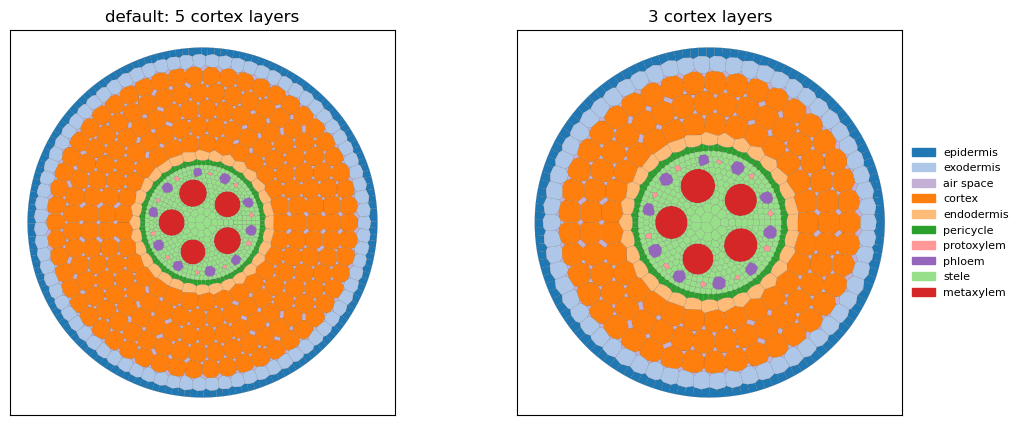

In [2]:
default = simulate()
thin = simulate({"cortex": {"n_layers": 3}})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
default.draw(axes[0], legend=False); axes[0].set_title("default: 5 cortex layers")
thin.draw(axes[1]); axes[1].set_title("3 cortex layers")
pd.DataFrame({"default": default.totals, "3 cortex layers": thin.totals})

Two layers of 40 µm fewer: the radius shrinks by 80 µm, from 0.41 to 0.33 mm, and the section loses about 150 cells.
The vessels are unchanged, since the stele is the same.

Another parameter, the aerenchyma: the share of the cortex turned into air channels. Some roots form them when the
soil lacks oxygen (waterlogging).

air share: 0.034 by default, 0.186 with aerenchyma


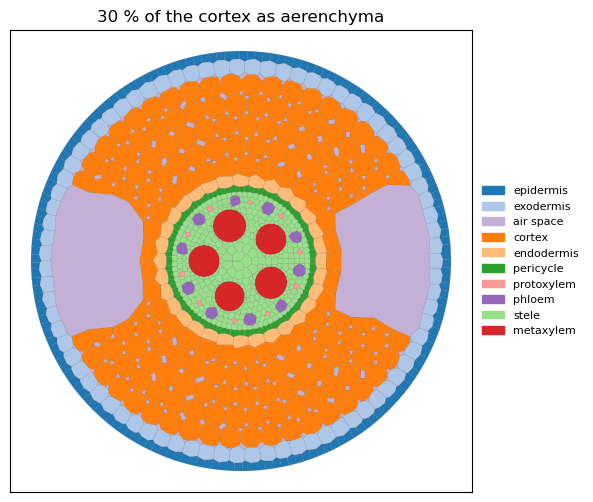

In [3]:
aerenchyma = simulate({"aerenchyma": {"aerenchyma_proportion": 0.3}})
fig, ax = plt.subplots(figsize=(6, 6))
aerenchyma.draw(ax)
ax.set_title("30 % of the cortex as aerenchyma")
print(f"air share: {default.totals['air_share']:.3f} by default, {aerenchyma.totals['air_share']:.3f} with aerenchyma")

## 3. The role of chance

The positions and shapes of the cells are drawn at random, around the rules the parameters set. The random draws come
from a **seed** (`seed=`). The same seed gives exactly the same section; another seed gives another section of the
same kind, as two roots of a plant differ.

In [4]:
rows = {f"seed {seed}": simulate(seed=seed).totals for seed in range(5)}
seeds = pd.DataFrame(rows).T
seeds

,radius,area,cells,vessels,mean_vessel_diameter,air_share
seed 0,0.410287,0.528841,1013.0,15.0,27.492075,0.033770
seed 1,0.410289,0.528847,1016.0,15.0,27.872020,0.033546
seed 2,0.410290,0.528848,1016.0,15.0,26.821552,0.033768
seed 3,0.410289,0.528846,1021.0,15.0,26.203815,0.033574
seed 4,0.410285,0.528836,1011.0,15.0,27.510089,0.033457


The radius does not change (it is set by the parameters), while the number of cells and the vessels' sizes vary
slightly. **To see the effect of a parameter, compare sections with the same seed**, as above (all used seed 0). To
draw conclusions about a genotype or a treatment, generate several seeds and compare the means.

## 4. Another preset: a dicotyledon root

A **preset** is a complete set of parameters. `for_root` (the default) is a monocotyledon root; `for_dicot_root` is a
dicotyledon root (such as a tomato or a bean): its xylem forms a star in the centre, outlined by a **cambium**, the
cells from which the root thickens later. Changes apply on top of the preset.

,tissue,cells,mean_cell_diameter,area,area_share
0,epidermis,248,18.074984,0.063681,0.056290
1,exodermis,119,32.991274,0.101740,0.089933
2,air space,621,7.348740,0.028241,0.024964
3,cortex,355,43.846251,0.536108,0.473889
4,endodermis,72,28.565516,0.046149,0.040793
5,pericycle,230,11.768063,0.025065,0.022156
6,phloem,51,15.957362,0.010234,0.009047
7,stele,1026,17.320011,0.243572,0.215304
8,cambium,81,20.726159,0.027513,0.024320
9,xylem,31,42.522963,0.048989,0.043304


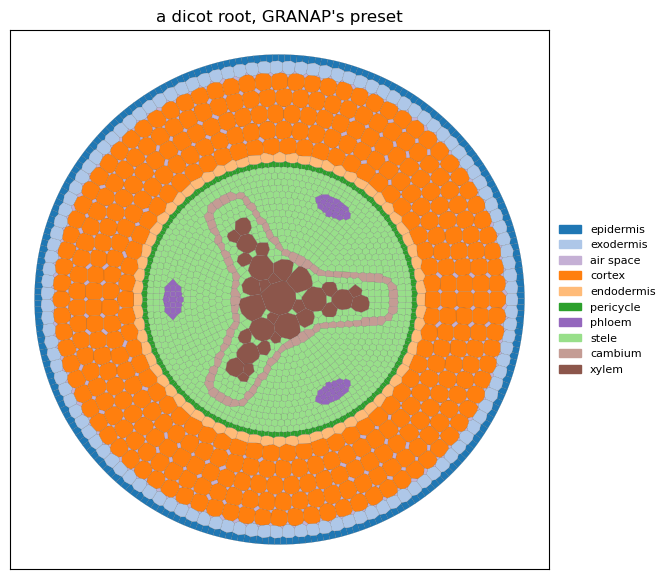

In [5]:
dicot = simulate(preset="for_dicot_root")
fig, ax = plt.subplots(figsize=(7, 7))
dicot.draw(ax)
ax.set_title("a dicot root, GRANAP's preset")
dicot.summary

`parameters(preset="for_dicot_root")` lists that preset's values.

## Try it yourself

1. Give the cortex 7 layers. Does the radius grow as the rule of tutorial 1 says?
2. Double the number of metaxylem vessels (`{"xylem": {"n_vascular_bundles": 10}}`). How do the totals change?
3. Run 3 seeds of the dicot root: how variable is its number of cells?

**Next:** `03_combine_parameters.ipynb`.